# Brickwork (2 Layers) vs. Staircase (3 Layers): Parallel Speed vs. Idle Decay

Because all $Z_i Z_{i+1}$ terms in the 1D Ising Hamiltonian commute with each other:
$$e^{-i (Z_0 Z_1 + Z_1 Z_2 + Z_2 Z_3)\Delta t} = e^{-i Z_0 Z_1 \Delta t} \cdot e^{-i Z_1 Z_2 \Delta t} \cdot e^{-i Z_2 Z_3 \Delta t}$$

we have a choice in how we schedule the `CZ` gates inside each Trotter step on a 4-qubit chain (`q0 — q1 — q2 — q3`):

| Schedule | `first_qubit` Loop | Unique Layers per Step | Mirrored Layers (2 Trotter Steps) | Qubits Idle per Layer |
| :--- | :--- | :---: | :---: | :--- |
| **Brickwork (Parallel)** | `for first_qubit in (1, 2):` (step `2`) | **2 unique layers** (`(0,1)+(2,3)`, then `(1,2)`) | **8 layers** | `0` idle in Even, `2` idle in Odd |
| **Staircase (Sequential)** | `for first_qubit in (1, 2, 3):` (step `3`) | **3 unique layers** (`(0,1)`, then `(1,2)`, then `(2,3)`) | **12 layers** | `2` idle in **every** layer |

### The Hardware Trade-Off
* Both circuits execute the **exact same ideal unitary** and contain the **exact same number of `CZ` gates** (12 `CZ` gates total in a 2-step mirror circuit).
* However, **Staircase takes $1.5\times$ more time layers (12 layers vs. 8 layers)**, meaning qubits spend 4 extra layers sitting idle and accumulating **1-qubit idle decoherence (`mean_rate_1q`)**.
* Using `twirling_strategy="active_circuit"` (Samplomatic's default, which twirls and models idle circuit wires inside each layer box), we can directly compare the **2-layer Brickwork** vs. **3-layer Staircase** schedules.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

from qiskit import QuantumCircuit
from qiskit.circuit import BoxOp, CircuitInstruction
from qiskit.quantum_info import Pauli, SparsePauliOp, PauliLindbladMap
from qiskit.transpiler import generate_preset_pass_manager

from qiskit_ibm_runtime import QuantumProgram
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh

# Samplomatic
import samplomatic
from samplomatic import Twirl, InjectNoise, ChangeBasis, build
from samplomatic.transpiler import generate_boxing_pass_manager
from samplomatic.utils import find_unique_box_instructions, get_annotation

# Local learner and simulator
from qiskit_aer import AerSimulator
from qiskit_noise_learning.aer_executor import AerExecutor
from qiskit_noise_learning.noise_learner import LearningOptions, NoiseLearner

In [10]:
def synthetic_noise_dict(
    unique_layers,
    seed: int = 42,
    mean_rate_1q: float = 2e-3,
    mean_rate_2q: float = 1e-2,
    mean_spam_rate: float = 1e-2,
) -> dict[str, PauliLindbladMap]:
    """Build synthetic Pauli-Lindblad noise maps for local AerExecutor noise learning."""
    rng = np.random.default_rng(seed)
    noise_dict = {}

    # Keep only gate boxes carrying InjectNoise
    unique_layers[:] = [
        inst for inst in unique_layers
        if get_annotation(inst.operation, InjectNoise) is not None
    ]

    # Collect all active physical Qubit objects across all layers in ascending index order
    all_qubits = sorted(
        {q for inst in unique_layers for q in inst.qubits if q._index is not None},
        key=lambda q: q._index,
    )
    all_active_qubits = {q._index for q in all_qubits}

    for idx, inst in enumerate(unique_layers):
        orig_phys = (inst.operation.body.metadata or {}).get(
            "orig_phys_qubits", sorted(q._index for q in inst.qubits)
        )
        if list(inst.qubits) != all_qubits:
            old_body = inst.operation.body
            q_map = [all_qubits.index(q) for q in inst.qubits]
            new_body = QuantumCircuit(len(all_qubits), old_body.num_clbits)
            new_body.compose(
                old_body,
                qubits=q_map,
                clbits=list(range(old_body.num_clbits)),
                inplace=True,
            )
            new_body.metadata = {"orig_phys_qubits": orig_phys}
            new_box = BoxOp(new_body, annotations=inst.operation.annotations)
            inst = CircuitInstruction(new_box, tuple(all_qubits), inst.clbits)
            unique_layers[idx] = inst
        else:
            inst.operation.body.metadata = {"orig_phys_qubits": orig_phys}

        inj_ann = get_annotation(inst.operation, InjectNoise)
        if inj_ann is None:
            continue
        tag_ref = inj_ann.ref
        num_layer_qubits = len(inst.qubits)
        sparse_terms = []

        # 1Q Pauli-Lindblad rates on each local qubit index (includes idle qubits in the layer)
        for local_i in range(num_layer_qubits):
            for pauli in ("X", "Y", "Z"):
                r1 = float(rng.uniform(0.5 * mean_rate_1q, 1.5 * mean_rate_1q))
                sparse_terms.append((pauli, [local_i], r1))

        # 2Q Pauli-Lindblad rates on each 2Q gate inside the box body
        box_circuit = inst.operation.body
        for sub_inst in box_circuit.data:
            if len(sub_inst.qubits) == 2:
                l0 = box_circuit.find_bit(sub_inst.qubits[0]).index
                l1 = box_circuit.find_bit(sub_inst.qubits[1]).index
                for pauli_2q, scale in [("ZZ", 1.0), ("XX", 0.5), ("YY", 0.5), ("IZ", 0.5), ("ZI", 0.5)]:
                    r2 = float(rng.uniform(0.5 * mean_rate_2q, 1.5 * mean_rate_2q) * scale)
                    sparse_terms.append((pauli_2q, [l0, l1], r2))

        noise_dict[tag_ref] = PauliLindbladMap.from_sparse_list(
            sparse_terms, num_qubits=num_layer_qubits
        )

    # SPAM noise for AerExecutor's active learning qubits
    num_active = len(all_active_qubits)
    if num_active > 0:
        p_terms = [("X", [i], float(rng.uniform(0.5 * mean_spam_rate, 1.5 * mean_spam_rate))) for i in range(num_active)]
        m_terms = [("X", [i], float(rng.uniform(0.5 * mean_spam_rate, 1.5 * mean_spam_rate))) for i in range(num_active)]
        noise_dict["P"] = PauliLindbladMap.from_sparse_list(p_terms, num_qubits=num_active)
        noise_dict["M"] = PauliLindbladMap.from_sparse_list(m_terms, num_qubits=num_active)

    return noise_dict

In [11]:
def local_result_to_dict(noise_result, unique_layers):
    """
    Local equivalent of NoiseLearnerV3Results.to_dict(unique_layers, unique_refs=False).
    Slices the 156-qubit global PauliLindbladMap down to the exact local qubits of each box.
    """
    global_noise_dict = noise_result.to_dict()
    refs_to_noise = {}

    for inst in unique_layers:
        inj_ann = get_annotation(inst.operation, InjectNoise)
        if inj_ann is None:
            continue
        ref = inj_ann.ref
        if ref in global_noise_dict:
            global_map = global_noise_dict[ref]
            box_body = inst.operation.body
            orig_phys = (box_body.metadata or {}).get("orig_phys_qubits")
            if orig_phys is not None:
                phys_qubits = orig_phys
            else:
                phys_qubits = sorted(q._index for q in inst.qubits)

            if global_map.num_qubits > len(phys_qubits):
                refs_to_noise[ref] = global_map.keep_qubits(phys_qubits)
            else:
                refs_to_noise[ref] = global_map

    return refs_to_noise

## Part 1: Constructing Brickwork (`stride=2`) vs. Staircase (`stride=3`) Trotter Circuits

We add a `stride` parameter (`stride=2` for 2-layer Brickwork, `stride=3` for 3-layer Staircase) to `construct_ising_circuit()` and draw both 1-step circuits side by side:

1. Brickwork Schedule (stride=2 -> 2 CZ columns per Trotter step):


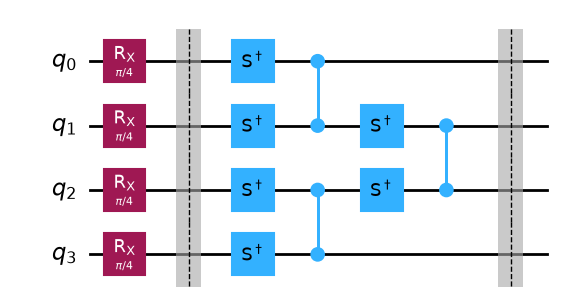

2. Staircase Schedule (stride=3 -> 3 CZ columns per Trotter step):


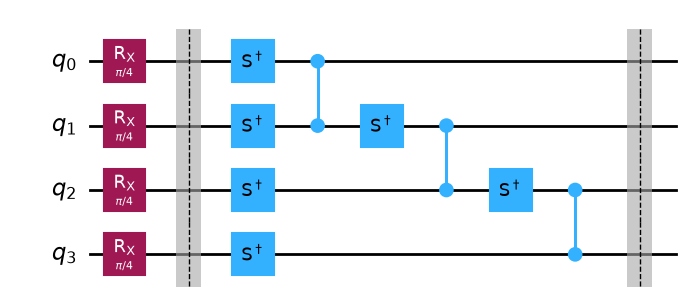

In [12]:
def construct_ising_circuit(
    num_qubits: int,
    num_trotter_steps: int,
    rx_angle: float,
    barrier: bool = True,
    stride: int = 2,
) -> QuantumCircuit:
    """
    Construct a Trotterized 1D Ising circuit.
    - stride=2 -> Brickwork (2 unique CZ layers per step on 4 qubits)
    - stride=3 -> Staircase (3 unique CZ layers per step on 4 qubits)
    """
    qc = QuantumCircuit(num_qubits)
    for _ in range(num_trotter_steps):
        qc.rx(rx_angle, range(num_qubits))
        if barrier:
            qc.barrier()
        for first_qubit in range(1, stride + 1):
            for idx in range(first_qubit, num_qubits, stride):
                qc.sdg([idx - 1, idx])
                qc.cz(idx - 1, idx)
        if barrier:
            qc.barrier()
    return qc


print("1. Brickwork Schedule (stride=2 -> 2 CZ columns per Trotter step):")
display(construct_ising_circuit(4, 1, np.pi / 4, stride=2).draw("mpl", fold=-1))

print("2. Staircase Schedule (stride=3 -> 3 CZ columns per Trotter step):")
display(construct_ising_circuit(4, 1, np.pi / 4, stride=3).draw("mpl", fold=-1))

## Part 2: Boxing and Learning Noise for Brickwork (2 Unique Layers) vs. Staircase (3 Unique Layers)

We use `twirling_strategy="active_circuit"` in `generate_boxing_pass_manager()` so every layer box spans all 4 circuit qubits (`q0..q3`), capturing the 1-qubit idle decoherence on the qubits that sit waiting during each layer.

Notice that the **exact same plotting code** produces **2 subplots** for Brickwork and **3 subplots** for Staircase!

In [13]:
backend = FakeMarrakesh()
isa_pm = generate_preset_pass_manager(backend=backend, optimization_level=0)

# Use twirling_strategy='active_circuit' so idle qubits inside each layer also experience 1Q idle decay
noise_learning_boxing_pm = generate_boxing_pass_manager(
    enable_gates=True,
    enable_measures=True,
    twirling_strategy="active_circuit",
    inject_noise_targets="gates",
    inject_noise_strategy="no_modification",
)

num_qubits = 4
num_trotter_steps = 2
rx_angle = np.pi / 4

def build_boxed_mirror(stride: int):
    ising_qc = construct_ising_circuit(
        num_qubits=num_qubits,
        num_trotter_steps=num_trotter_steps,
        rx_angle=rx_angle,
        barrier=False,
        stride=stride,
    )
    mirror_qc = QuantumCircuit(num_qubits)
    mirror_qc.compose(ising_qc, inplace=True)
    mirror_qc.barrier()
    mirror_qc.compose(ising_qc.inverse(), inplace=True)
    mirror_qc.measure_all()
    mirror_isa = isa_pm.run(mirror_qc)
    boxed_qc = noise_learning_boxing_pm.run(mirror_isa)
    unique_layers = find_unique_box_instructions(
        boxed_qc,
        normalize_annotations=None,
        undress_boxes=True,
    )
    return boxed_qc, unique_layers


boxed_brick, unique_brick = build_boxed_mirror(stride=2)
boxed_stair, unique_stair = build_boxed_mirror(stride=3)

# Learn noise for Brickwork (2 layers) and Staircase (3 layers)
nl_options = LearningOptions(
    num_randomizations=8,
    shots_per_randomization=32,
    fragment_depths=[1, 2, 4],
)

noise_dict_brick = synthetic_noise_dict(unique_brick, mean_rate_1q=5e-3, mean_rate_2q=1e-2)
exec_brick = AerExecutor(AerSimulator(), noise_dict=noise_dict_brick, 
                         warn_absent=False, #root_seed=2026
                         )
res_brick = NoiseLearner(backend, options=nl_options, executor=exec_brick).run(unique_brick).result()
refs_to_noise_brick = local_result_to_dict(res_brick, unique_brick)

noise_dict_stair = synthetic_noise_dict(unique_stair, mean_rate_1q=5e-3, mean_rate_2q=1e-2)
exec_stair = AerExecutor(AerSimulator(), noise_dict=noise_dict_stair, 
                         warn_absent=False, #root_seed=2026
                         )
res_stair = NoiseLearner(backend, options=nl_options, executor=exec_stair).run(unique_stair).result()
refs_to_noise_stair = local_result_to_dict(res_stair, unique_stair)

print(f"Brickwork learned {len(refs_to_noise_brick)} unique layers: {list(refs_to_noise_brick.keys())}")
print(f"Staircase learned {len(refs_to_noise_stair)} unique layers: {list(refs_to_noise_stair.keys())}")

Brickwork learned 2 unique layers: ['ra79A', 'r5a7A']
Staircase learned 4 unique layers: ['rbd3A', 'r5a7A', 'ra79A', 'r33eA']


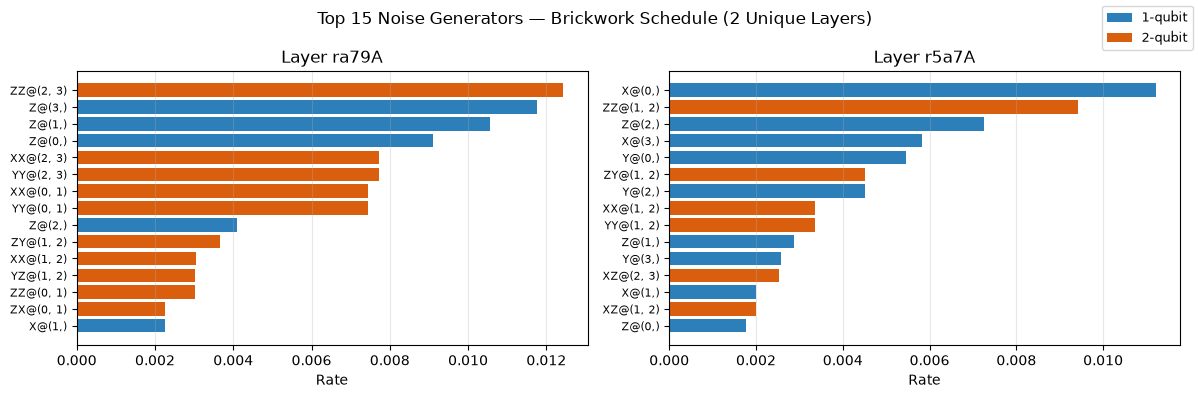

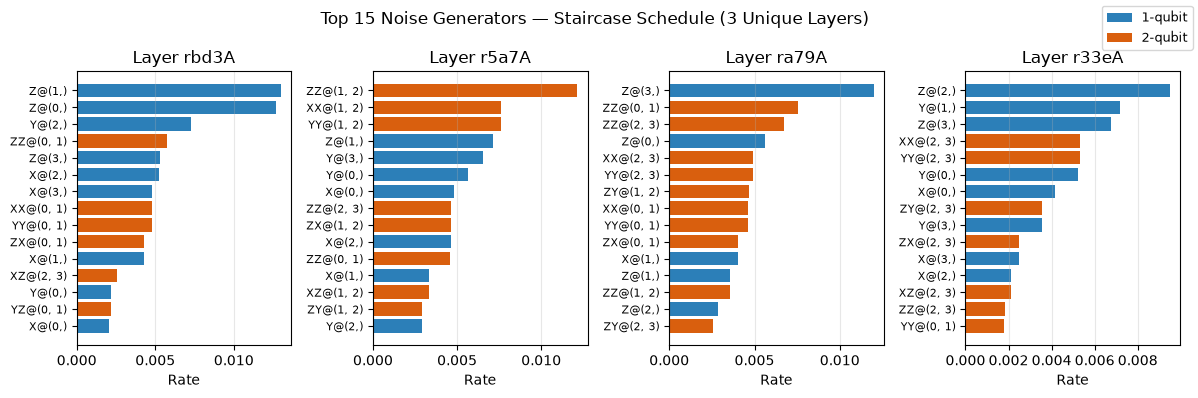

In [14]:
# Exact same plotting code from part-1.ipynb, run on Brickwork (2 layers) and Staircase (3 layers)
for schedule_name, refs_dict in [
    ("Brickwork Schedule (2 Unique Layers)", refs_to_noise_brick),
    ("Staircase Schedule (3 Unique Layers)", refs_to_noise_stair),
]:
    fig, axes = plt.subplots(1, len(refs_dict), figsize=(12, 4))
    if len(refs_dict) == 1:
        axes = [axes]

    for ax, (ref, plm) in zip(axes, refs_dict.items()):
        gens = sorted(plm.to_sparse_list(), key=lambda g: -abs(g[2]))[:15]
        labels = [f"{p}@{tuple(q)}" for p, q, _ in gens]
        rates = [r for _, _, r in gens]
        colors = ["#2c7fb8" if len(p) == 1 else "#d95f0e" for p, _, _ in gens]
        ax.barh(range(len(labels)), rates, color=colors)
        ax.set_yticks(range(len(labels)))
        ax.set_yticklabels(labels, fontsize=8)
        ax.invert_yaxis()
        ax.set_xlabel("Rate")
        ax.set_title(f"Layer {ref}")
        ax.grid(axis="x", alpha=0.3)

    fig.legend(
        handles=[
            Patch(facecolor="#2c7fb8", label="1-qubit"),
            Patch(facecolor="#d95f0e", label="2-qubit"),
        ],
        loc="upper right",
        fontsize=9,
    )
    fig.suptitle(f"Top 15 Noise Generators — {schedule_name}")
    plt.tight_layout()
    plt.show()

## Part 3: Sweeping Idle 1-Qubit Noise (`mean_rate_1q`) — Why Staircase Suffers More Idle Decay

Let's sweep the 1-qubit / idle noise rate `mean_rate_1q` across `[1e-3, 5e-3, 1e-2, 2e-2]` while keeping the 2-qubit `CZ` gate noise fixed (`mean_rate_2q = 1e-2`).

* At very small `mean_rate_1q` (`1e-3`), Brickwork and Staircase give nearly identical $\langle Z \rangle$ because they have the exact same 12 `CZ` gates.
* As `mean_rate_1q` increases, **Staircase (12 layers)** drops noticeably faster than **Brickwork (8 layers)** because the qubits spend 4 extra layers sitting idle!

In [15]:
idle_rates_1q = [1e-3, 5e-3, 1e-2, 2e-2]
rate_labels = ["1e-3 (Low)", "5e-3 (Med)", "1e-2 (High)", "2e-2 (V.High)"]

template_brick, samplex_brick = build(boxed_brick)
template_stair, samplex_stair = build(boxed_stair)

brick_z_per_rate = []
stair_z_per_rate = []

for r1q in idle_rates_1q:
    # True synthetic noise maps for this 1Q idle rate
    nd_brick = synthetic_noise_dict(unique_brick, mean_rate_1q=r1q, mean_rate_2q=1e-2)
    nd_stair = synthetic_noise_dict(unique_stair, mean_rate_1q=r1q, mean_rate_2q=1e-2)

    plm_brick = {k: v for k, v in nd_brick.items() if k not in ("P", "M")}
    plm_stair = {k: v for k, v in nd_stair.items() if k not in ("P", "M")}

    # Run Brickwork (8 total gate layers in 2-step mirror circuit)
    args_b = samplex_brick.inputs().make_broadcastable().bind(pauli_lindblad_maps=plm_brick)
    prog_b = QuantumProgram(shots=64)
    prog_b.append_samplex_item(circuit=template_brick, samplex=samplex_brick, samplex_arguments=args_b, shape=(32,))
    res_b = exec_brick.run(prog_b).result()[0]
    z_b = (1 - 2 * np.bitwise_xor(res_b["meas"], res_b["measurement_flips.meas"]).astype(np.int8)).reshape(-1, num_qubits).mean(axis=0)
    brick_z_per_rate.append(z_b)

    # Run Staircase (12 total gate layers in 2-step mirror circuit)
    args_s = samplex_stair.inputs().make_broadcastable().bind(pauli_lindblad_maps=plm_stair)
    prog_s = QuantumProgram(shots=64)
    prog_s.append_samplex_item(circuit=template_stair, samplex=samplex_stair, samplex_arguments=args_s, shape=(32,))
    res_s = exec_stair.run(prog_s).result()[0]
    z_s = (1 - 2 * np.bitwise_xor(res_s["meas"], res_s["measurement_flips.meas"]).astype(np.int8)).reshape(-1, num_qubits).mean(axis=0)
    stair_z_per_rate.append(z_s)

brick_z_per_rate = np.array(brick_z_per_rate)  # shape: (4 rates, 4 qubits)
stair_z_per_rate = np.array(stair_z_per_rate)  # shape: (4 rates, 4 qubits)

brick_means = brick_z_per_rate.mean(axis=1)
stair_means = stair_z_per_rate.mean(axis=1)

print(f"{'1Q Idle Rate':<16}{'Brickwork Mean ⟨Z⟩ (8 layers)':<32}{'Staircase Mean ⟨Z⟩ (12 layers)':<32}{'Brickwork Advantage'}")
print("-" * 98)
for lbl, bm, sm in zip(rate_labels, brick_means, stair_means):
    print(f"{lbl:<16}{bm:<32.4f}{sm:<32.4f}{bm - sm:+.4f}")

1Q Idle Rate    Brickwork Mean ⟨Z⟩ (8 layers)   Staircase Mean ⟨Z⟩ (12 layers)  Brickwork Advantage
--------------------------------------------------------------------------------------------------
1e-3 (Low)      0.8364                          0.6018                          +0.2346
5e-3 (Med)      0.6265                          0.5105                          +0.1160
1e-2 (High)     0.5327                          0.5051                          +0.0276
2e-2 (V.High)   0.2385                          0.2712                          -0.0327


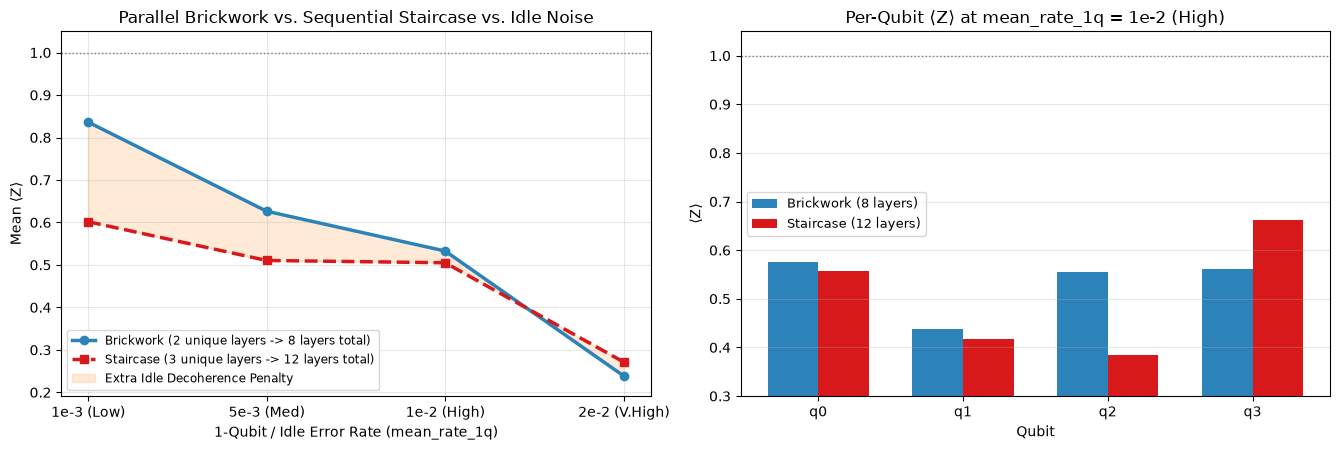

In [16]:
# Visualize: (1) Brickwork vs. Staircase Mean ⟨Z⟩ Across 1Q Idle Rates & (2) Per-Qubit Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.6))

x_idx = np.arange(len(idle_rates_1q))
ax1.plot(x_idx, brick_means, marker="o", lw=2.5, color="#2b83ba", label="Brickwork (2 unique layers -> 8 layers total)")
ax1.plot(x_idx, stair_means, marker="s", lw=2.5, color="#d7191c", ls="--", label="Staircase (3 unique layers -> 12 layers total)")
ax1.fill_between(x_idx, stair_means, brick_means, color="#fdae61", alpha=0.25, label="Extra Idle Decoherence Penalty")

ax1.axhline(1.0, color="gray", ls=":", lw=1)
ax1.set_xticks(x_idx)
ax1.set_xticklabels(rate_labels)
ax1.set_xlabel("1-Qubit / Idle Error Rate (mean_rate_1q)")
ax1.set_ylabel("Mean ⟨Z⟩")
ax1.set_ylim(min(0.3, float(stair_means.min()) - 0.08), 1.05)
ax1.set_title("Parallel Brickwork vs. Sequential Staircase vs. Idle Noise")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8.5)

# Right panel: Per-qubit ⟨Z⟩ at high idle noise (mean_rate_1q = 1e-2, index 2)
idx_show = 2
qx = np.arange(num_qubits)
w = 0.35
ax2.bar(qx - w / 2, brick_z_per_rate[idx_show], width=w, color="#2b83ba", label="Brickwork (8 layers)")
ax2.bar(qx + w / 2, stair_z_per_rate[idx_show], width=w, color="#d7191c", label="Staircase (12 layers)")
ax2.axhline(1.0, color="gray", ls=":", lw=1)
ax2.set_xticks(qx)
ax2.set_xticklabels([f"q{q}" for q in qx])
ax2.set_xlabel("Qubit")
ax2.set_ylabel("⟨Z⟩")
ax2.set_ylim(min(0.3, float(stair_z_per_rate[idx_show].min()) - 0.08), 1.05)
ax2.set_title(f"Per-Qubit ⟨Z⟩ at mean_rate_1q = {rate_labels[idx_show]}")
ax2.grid(axis="y", alpha=0.3)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()